# PlantSeg Stage 5 -- Figure 24 ONLY (trimmed 2026-09-20)

**This is a trimmed copy of the full Stage 5 decision-support notebook, kept to just what
regenerates Figure 24.** The full notebook's batch-validation cells (full test-set run,
Fisher's exact / Mann-Whitney / logistic-regression checks feeding Table 15) are NOT
included here -- those were already run and reported; re-run the full
`notebook32094e37db.ipynb` (or `stage5-fig24-update.ipynb`) only if those numbers need to
be regenerated too. This notebook processes 8 demo images and should finish in well under
a minute of GPU time once the models are loaded.

**Change from the original Figure 24** (Reviewer 2: "clarify the darker/lighter convention
for the predicted lesion"): the predicted-lesion overlay (column 2) now carries a legend
patch stating it is a *binary* mask (red = lesion, no overlay = background, not a
continuous score), and the Grad-CAM overlay (column 3) now has a shared colour-bar for its
jet colormap (0 = low attribution -> 1 = high). Both conventions are also restated in the
figure's suptitle. Output filename is unchanged (`f24_decision_support_demo.png`), so no
other file needs updating.

> Internet **ON** (installs `timm`/`segmentation-models-pytorch`/`grad-cam`/`statsmodels`
> -- `statsmodels` isn't actually used by this trimmed notebook but is left in the install
> line to match the original exactly). Attach the PlantSeg dataset and the two checkpoint
> files (`ConvNeXtV2Tiny_best.pt`, `DeepLabV3Plus_efficientnet-b3.pt` -- both sitting
> together in your `PlantSeg_Deployment_Space` folder) as Kaggle input datasets before
> running.


In [1]:
!pip install -q timm segmentation-models-pytorch grad-cam statsmodels
import os, glob, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
import torchvision.transforms as T
import timm
import segmentation_models_pytorch as smp
from pytorch_grad_cam import GradCAM
warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED); torch.cuda.manual_seed_all(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.5/44.5 kB 2.2 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 9.1 MB/s eta 0:00:00
Device: cuda


In [2]:
# ============ CONFIG (auto-detect paths, mirrors S1/S2 trainer notebooks) ============
def find_data_root():
    hits = glob.glob("/kaggle/input/**/Metadata.csv", recursive=True)
    assert hits, "Metadata.csv not found anywhere under /kaggle/input -- attach the PlantSeg dataset."
    return Path(hits[0]).parent

DATA_ROOT = find_data_root()
print("DATA_ROOT:", DATA_ROOT)

def find_ckpt(name):
    hits = glob.glob(f"/kaggle/input/**/{name}", recursive=True)
    assert hits, f"Could not find {name} under /kaggle/input -- attach the checkpoint dataset."
    return hits[0]

CLS_CKPT = find_ckpt("ConvNeXtV2Tiny_best.pt")
SEG_CKPT = find_ckpt("DeepLabV3Plus_efficientnet-b3.pt")
print("Classifier checkpoint:", CLS_CKPT)
print("Segmenter checkpoint :", SEG_CKPT)

IMG_SIZE_CLS = 384   # matches Stage-1 ConvNeXtV2-Tiny training
IMG_SIZE_SEG = 512   # matches Stage-2 DeepLabV3+ training
MEAN = [0.485, 0.456, 0.406]; STD = [0.229, 0.224, 0.225]
OUTDIR = Path("/kaggle/working/stage5_decision_support"); OUTDIR.mkdir(parents=True, exist_ok=True)

DATA_ROOT: /kaggle/input/datasets/alenmaruf/plantseg/plantseg
Classifier checkpoint: /kaggle/input/datasets/alenmaruf/deploy-model-pt/ConvNeXtV2Tiny_best.pt
Segmenter checkpoint : /kaggle/input/datasets/alenmaruf/deploy-model-pt/DeepLabV3Plus_efficientnet-b3.pt


In [3]:
# ============ CLASS NAMES (must match the exact ordering used at training time) ============
meta = pd.read_csv(DATA_ROOT / "Metadata.csv", encoding="utf-8-sig")
meta["split"] = meta["Split"].map({"Training": "train", "Validation": "val", "Test": "test"})
meta["filepath"] = meta.apply(lambda r: DATA_ROOT / "images" / r["split"] / r["Name"], axis=1)
meta["label"] = meta["Disease"]
meta = meta[meta["filepath"].apply(lambda p: Path(p).exists())].reset_index(drop=True)
CLASS_NAMES = sorted(meta["label"].unique().tolist())
NUM_CLASSES = len(CLASS_NAMES)
test_df = meta[meta.split == "test"].reset_index(drop=True)
print(f"{NUM_CLASSES} classes | {len(test_df)} test images available for the demo")

115 classes | 1561 test images available for the demo


In [4]:
# ============ MODEL DEFINITIONS (identical to the Stage-1 / Stage-2 trainer notebooks) ============
def build_classifier(num_classes):
    return timm.create_model("convnextv2_tiny", pretrained=False, num_classes=num_classes)

class SegNet(nn.Module):
    """DeepLabV3+ / EfficientNet-B3, binary lesion-vs-background, unified full-res logits."""
    def __init__(self, num_classes=2):
        super().__init__()
        self.net = smp.DeepLabV3Plus(encoder_name="efficientnet-b3", encoder_weights=None,
                                      in_channels=3, classes=num_classes)
    def forward(self, x):
        return self.net(x)

def load_state(model, ckpt_path):
    raw = torch.load(ckpt_path, map_location="cpu")
    if isinstance(raw, dict):
        for key in ("state_dict", "model_state_dict", "model", "best_state"):
            if key in raw and isinstance(raw[key], dict):
                raw = raw[key]; break
    raw = {k.replace("module.", ""): v for k, v in raw.items()}
    missing, unexpected = model.load_state_dict(raw, strict=False)
    if missing or unexpected:
        print(f"  [load_state] missing={len(missing)} unexpected={len(unexpected)} "
              "(safe to ignore if only BN num_batches_tracked / head aux keys)")
    return model

clf = build_classifier(NUM_CLASSES)
clf = load_state(clf, CLS_CKPT).to(device).eval()

seg = SegNet(num_classes=2)
seg = load_state(seg, SEG_CKPT).to(device).eval()
print("Both models loaded.")

Both models loaded.


In [5]:
# ============ PREPROCESSING (matches eval-time transforms used during training) ============
cls_tf = T.Compose([T.Resize((IMG_SIZE_CLS, IMG_SIZE_CLS)), T.ToTensor(), T.Normalize(MEAN, STD)])
seg_tf = T.Compose([T.Resize((IMG_SIZE_SEG, IMG_SIZE_SEG)), T.ToTensor(), T.Normalize(MEAN, STD)])

# Grad-CAM on the classifier's last ConvNeXtV2 stage (matches Stage-1's own `tgt()` mapping)
cam_extractor = GradCAM(model=clf, target_layers=[clf.stages[-1]])

In [6]:
# ============ CORE PIPELINE: image -> class + severity + faithfulness-gated confidence ============
def diagnose_image(image_path):
    img = Image.open(image_path).convert("RGB")

    # 1) Classification
    x_cls = cls_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        logits = clf(x_cls)
        probs = F.softmax(logits, dim=1)[0]
    pred_idx = int(probs.argmax())
    pred_class = CLASS_NAMES[pred_idx]
    cls_confidence = float(probs[pred_idx])

    # 2) Lesion segmentation -> severity (lesion-area ratio, matching Section 3.4 of the paper)
    x_seg = seg_tf(img).unsqueeze(0).to(device)
    with torch.no_grad():
        seg_logits = seg(x_seg)
        pred_mask = seg_logits.argmax(1)[0].cpu().numpy().astype(np.uint8)  # (H,W) in {0,1}
    severity = float(pred_mask.mean())

    # 3) Grad-CAM for the predicted class, at the classifier's own input resolution
    cam = cam_extractor(input_tensor=x_cls, targets=None)[0]  # (H,W) in [0,1], size IMG_SIZE_CLS

    # 4) Faithfulness-gated confidence flag (deployment-time proxy for Section 4's CAM-GT check):
    #    resize CAM and predicted mask to a common grid, binarise CAM at the model's OWN
    #    predicted severity fraction (mirrors the paper's own-area-fraction threshold, the only
    #    version of that rule available without ground truth), then check overlap/pointing.
    cam_img = Image.fromarray((cam * 255).astype(np.uint8)).resize((IMG_SIZE_SEG, IMG_SIZE_SEG))
    cam_rs = np.asarray(cam_img).astype(np.float32) / 255.0
    tau = max(severity, 1e-3)
    thresh = np.quantile(cam_rs, 1 - tau)
    cam_bin = (cam_rs >= thresh).astype(np.uint8)
    inter = np.logical_and(cam_bin, pred_mask).sum()
    union = np.logical_or(cam_bin, pred_mask).sum()
    cam_pred_iou = float(inter / union) if union > 0 else 0.0
    peak_yx = np.unravel_index(np.argmax(cam_rs), cam_rs.shape)
    pointing_hit = bool(pred_mask[peak_yx] == 1)
    confidence_flag = "HIGH" if pointing_hit else "LOW"

    return dict(image_path=str(image_path), pred_class=pred_class, cls_confidence=cls_confidence,
                severity=severity, cam_pred_iou=cam_pred_iou, pointing_hit=pointing_hit,
                confidence_flag=confidence_flag, img=img, pred_mask=pred_mask, cam=cam_rs)

In [7]:
# ============ VISUALISATION (REVISED per Reviewer 2: explicit shading/colour conventions) ============
# R2: "clarify the darker/lighter convention for the predicted lesion." Adds: a legend patch
# stating the predicted-lesion overlay is a BINARY mask (red = lesion, no overlay =
# background, not a continuous intensity), and a shared colour-bar for the Grad-CAM panel's
# jet overlay (0 = low attribution -> 1 = high), both stated again in the figure caption.

def plot_diagnosis(res, ax_row, cam_im_holder):
    img_rs = res["img"].resize((IMG_SIZE_SEG, IMG_SIZE_SEG))
    ax_row[0].imshow(img_rs); ax_row[0].set_title("Input"); ax_row[0].axis("off")

    ax_row[1].imshow(img_rs)
    ax_row[1].imshow(res["pred_mask"], cmap="Reds", alpha=0.45, vmin=0, vmax=1)
    ax_row[1].set_title(f"Predicted lesion (red overlay)\nseverity={res['severity']*100:.1f}%",
                         fontsize=9)
    ax_row[1].axis("off")

    ax_row[2].imshow(img_rs)
    cam_im = ax_row[2].imshow(res["cam"], cmap="jet", alpha=0.45, vmin=0, vmax=1)
    ax_row[2].set_title("Grad-CAM (jet overlay)\n(classifier attention)", fontsize=9)
    ax_row[2].axis("off")
    cam_im_holder.append(cam_im)

    flag_color = "forestgreen" if res["confidence_flag"] == "HIGH" else "firebrick"
    ax_row[3].axis("off")
    ax_row[3].text(0.02, 0.75, res["pred_class"], fontsize=11, weight="bold", wrap=True)
    ax_row[3].text(0.02, 0.55, f"class conf.: {res['cls_confidence']*100:.1f}%", fontsize=9)
    ax_row[3].text(0.02, 0.40, f"severity: {res['severity']*100:.1f}%", fontsize=9)
    ax_row[3].text(0.02, 0.25, f"CAM-mask IoU: {res['cam_pred_iou']:.2f}", fontsize=9)
    ax_row[3].text(0.02, 0.05, f"confidence: {res['confidence_flag']}", fontsize=11, weight="bold",
                    color=flag_color)


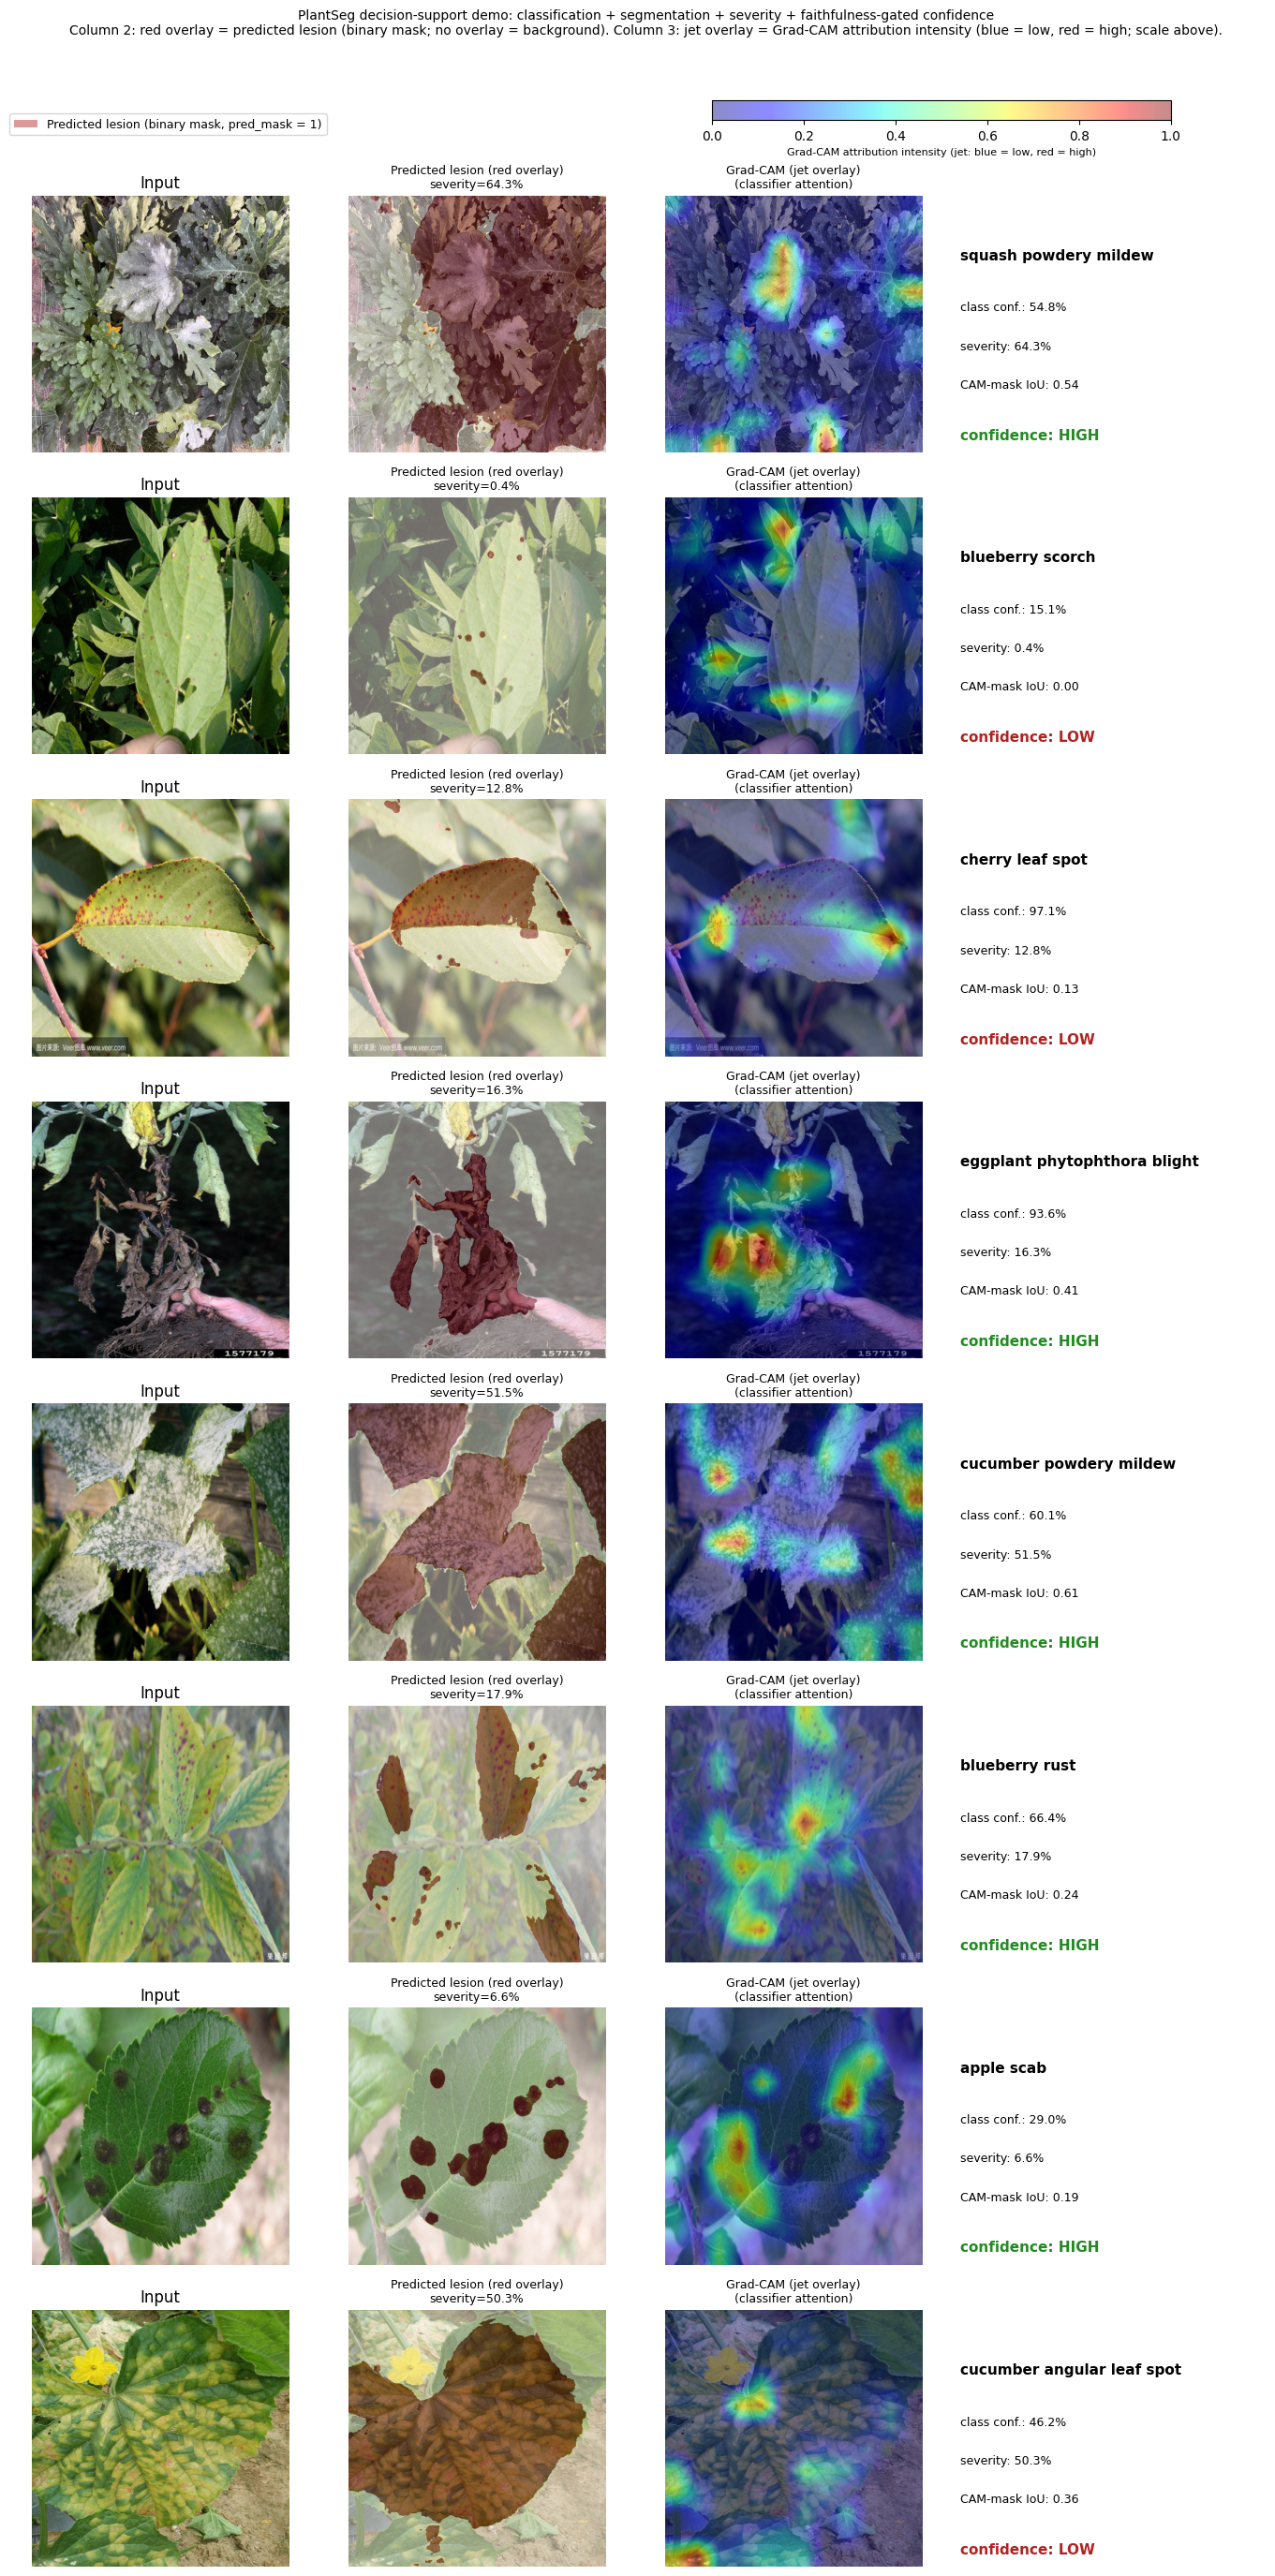

HIGH-confidence: 5/8 | pointing-hit rate: 0.62 | mean CAM-mask IoU: 0.310


,image,true_disease,pred_class,cls_confidence,severity,cam_pred_iou,pointing_hit,confidence_flag
0,zucchini_powdery_mildew_Bing_0010.jpg,zucchini powdery mildew,squash powdery mildew,0.548085,0.643456,0.541148,True,HIGH
1,soybean_frog_eye_leaf_spot_Bing_0126.jpg,soybean frog eye leaf spot,blueberry scorch,0.150612,0.004147,0.000000,False,LOW
2,cherry_leaf_spot_63.jpg,cherry leaf spot,cherry leaf spot,0.970568,0.127949,0.130401,False,LOW
3,eggplant_phytophthora_blight_Bing_0022.jpg,eggplant phytophthora blight,eggplant phytophthora blight,0.936025,0.162552,0.406113,True,HIGH
4,cucumber_powdery_mildew_google_0000.jpg,cucumber powdery mildew,cucumber powdery mildew,0.600774,0.514507,0.608636,True,HIGH
5,blueberry_rust_6.jpg,blueberry rust,blueberry rust,0.664010,0.178749,0.244284,True,HIGH
6,apple_scab_google_0023.jpg,apple scab,apple scab,0.290358,0.065990,0.187419,True,HIGH
7,cucumber_angular_leaf_spot_79.jpg,cucumber angular leaf spot,cucumber angular leaf spot,0.462248,0.502773,0.361361,False,LOW


In [8]:
# ============ RUN THE DEMO over a small stratified sample (REVISED per Reviewer 2) ==========
# R2: "Figure 24 is more readable, but the same applies -- clarify the darker/lighter
# convention for the predicted lesion." This cell now attaches: (1) a legend patch stating
# the predicted-lesion overlay convention; (2) a shared colour-bar for the Grad-CAM jet
# overlay; (3) both conventions restated explicitly in the suptitle. Saved under the SAME
# filename (f24_decision_support_demo.png) so paper.tex needs no path change.

N_DEMO = 8
sample = test_df.sample(min(N_DEMO, len(test_df)), random_state=SEED).reset_index(drop=True)

results, rows = [], []
cam_im_holder = []
fig, axes = plt.subplots(len(sample), 4, figsize=(14, 3.3 * len(sample)))
for i, r in sample.iterrows():
    res = diagnose_image(r.filepath)
    results.append(res)
    plot_diagnosis(res, axes[i], cam_im_holder)
    rows.append({"image": r.Name, "true_disease": r.Disease, "pred_class": res["pred_class"],
                 "cls_confidence": res["cls_confidence"], "severity": res["severity"],
                 "cam_pred_iou": res["cam_pred_iou"], "pointing_hit": res["pointing_hit"],
                 "confidence_flag": res["confidence_flag"]})

from matplotlib.patches import Patch
lesion_patch = Patch(facecolor="firebrick", alpha=0.45, label="Predicted lesion (binary mask, pred_mask = 1)")
fig.legend(handles=[lesion_patch], loc="upper left", bbox_to_anchor=(0.01, 1.0), fontsize=9, frameon=True)

if cam_im_holder:
    cbar_ax = fig.add_axes([0.55, 0.995, 0.35, 0.008])
    cbar = fig.colorbar(cam_im_holder[0], cax=cbar_ax, orientation="horizontal")
    cbar.set_label("Grad-CAM attribution intensity (jet: blue = low, red = high)", fontsize=8)

plt.suptitle(
    "PlantSeg decision-support demo: classification + segmentation + severity + "
    "faithfulness-gated confidence\n"
    "Column 2: red overlay = predicted lesion (binary mask; no overlay = background). "
    "Column 3: jet overlay = Grad-CAM attribution intensity (blue = low, red = high; scale above).",
    y=1.04, fontsize=10)
plt.tight_layout()
plt.savefig(OUTDIR / "f24_decision_support_demo.png", dpi=200, bbox_inches="tight")
plt.show()

log = pd.DataFrame(rows)
log.to_csv(OUTDIR / "decision_support_demo_log.csv", index=False)
print(f"HIGH-confidence: {(log.confidence_flag=='HIGH').sum()}/{len(log)} "
      f"| pointing-hit rate: {log.pointing_hit.mean():.2f} "
      f"| mean CAM-mask IoU: {log.cam_pred_iou.mean():.3f}")
log
